# Problem Set 2. Neural networks & optimisation

**Course:** Analysis of Unstructured Data  
**Instructor:** Janusz Szwabiński  
**Goal:** Derive the deep-learning backbone once, so it can be reused for text, images and audio.  

---


In [1]:
# Setup environment & imports
import sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'


### Problem 1 [Theory] (Softmax + cross-entropy)


**Task:** For logits $z \in \mathbb{R}^K$, softmax $p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$ and one-hot target $y$, show that the cross-entropy loss $L = -\sum_k y_k \log p_k$ has gradient $\frac{\partial L}{\partial z} = p-y$. Explain why this clean form is the reason softmax and cross-entropy are always paired.

---

### Derivation

**Step 1: Define softmax and cross-entropy**

The softmax function converts logits into class probabilities:

$$
p_k = \frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}
$$

The cross-entropy loss for a one-hot target vector $y$, where $\sum_{k=1}^{K}y_k=1$, is:

$$
L=-\sum_{k=1}^{K}y_k\log p_k
$$

**Step 2: Substitute softmax into the loss function**

$$
L=-\sum_{k=1}^{K}y_k
\log\left(\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}\right)
$$

Using logarithm properties and $\sum_{k=1}^{K}y_k=1$:

$$
L=-\sum_{k=1}^{K}y_kz_k+
\log\left(\sum_{j=1}^{K}e^{z_j}\right)
$$

**Step 3: Compute the gradient with respect to $z_i$**

Differentiating both terms:

$$
\frac{\partial L}{\partial z_i}
=
-\frac{\partial}{\partial z_i}\sum_{k=1}^{K}y_kz_k
+
\frac{\partial}{\partial z_i}
\log\left(\sum_{j=1}^{K}e^{z_j}\right)
$$

The first term gives $-y_i$. Applying the chain rule to the second term:

$$
\frac{\partial L}{\partial z_i}
=
-y_i+\frac{e^{z_i}}{\sum_{j=1}^{K}e^{z_j}}
$$

Since the fraction is the softmax probability $p_i$:

$$
\frac{\partial L}{\partial z_i}=p_i-y_i
$$

Therefore, in vector form:

$$
\nabla_z L=p-y
$$

---

### Why Are Softmax and Cross-Entropy Paired?

Softmax converts logits into probabilities, while cross-entropy measures how well these probabilities match the true labels.

Their combination produces the simple gradient $\nabla_z L=p-y$, which:

- Simplifies backpropagation by avoiding explicit computation of the softmax Jacobian.
- Provides a direct error signal: predicted probabilities minus true labels.
- Enables efficient gradient-based optimization.

**Conclusion:** Softmax and cross-entropy are commonly paired because their combination provides a simple and computationally efficient gradient for training multi-class classification models.


### Problem 2 [Theory] (Backpropagation)

**Task:** Consider a two-layer MLP $h = \sigma(W_1x + b_1)$, $\hat{y} = \operatorname{softmax}(W_2h + b_2)$ with cross-entropy loss. Derive $\frac{\partial L}{\partial W_2}$, $\frac{\partial L}{\partial b_2}$, $\frac{\partial L}{\partial W_1}$, $\frac{\partial L}{\partial b_1}$ explicitly using the chain rule, for a general elementwise activation $\sigma$.

---

### Derivation

**Step 1: Define the forward pass**

Let $x\in\mathbb{R}^d$ be the input, $h\in\mathbb{R}^m$ the hidden-layer output, and $\hat{y}\in\mathbb{R}^K$ the predicted class probabilities.

The forward pass is defined as:

$$
a_1=W_1x+b_1,\qquad h=\sigma(a_1)
$$

$$
a_2=W_2h+b_2,\qquad \hat{y}=\operatorname{softmax}(a_2)
$$

where $\sigma$ is an elementwise activation function and:

$$
W_1\in\mathbb{R}^{m\times d},\quad b_1\in\mathbb{R}^m,
\quad W_2\in\mathbb{R}^{K\times m},\quad b_2\in\mathbb{R}^K
$$

The cross-entropy loss for a one-hot target vector $y$ is:

$$
L=-\sum_{k=1}^{K}y_k\log\hat{y}_k
$$

**Step 2: Compute the gradients for the output layer**

From Problem 1, the gradient of softmax combined with cross-entropy is:

$$
\delta_2=\frac{\partial L}{\partial a_2}=\hat{y}-y
$$

Since $a_2=W_2h+b_2$, we apply the chain rule elementwise. For each weight $(W_2)_{kj}$:

$$
\frac{\partial L}{\partial (W_2)_{kj}}
=
\frac{\partial L}{\partial (a_2)_k}
\frac{\partial (a_2)_k}{\partial (W_2)_{kj}}
=
(\delta_2)_k h_j
$$

Therefore:

$$
\frac{\partial L}{\partial W_2}=\delta_2h^\top=(\hat{y}-y)h^\top
$$

Similarly, since $\frac{\partial (a_2)_k}{\partial (b_2)_k}=1$:

$$
\frac{\partial L}{\partial b_2}=\delta_2=\hat{y}-y
$$

**Step 3: Backpropagate the error to the hidden layer**

Using the chain rule, the gradient with respect to the hidden-layer output is:

$$
\frac{\partial L}{\partial h}=W_2^\top\delta_2
$$

Since $h=\sigma(a_1)$ and $\sigma$ acts elementwise:

$$
\frac{\partial h}{\partial a_1}
=\operatorname{diag}(\sigma'(a_1))
$$

Thus, the hidden-layer error is:

$$
\delta_1=\frac{\partial L}{\partial a_1}
=
\left(W_2^\top\delta_2\right)\odot\sigma'(a_1)
$$

where $\odot$ denotes elementwise multiplication.

**Step 4: Compute the gradients for the first layer**

Since $a_1=W_1x+b_1$, applying the chain rule to each weight $(W_1)_{ij}$:

$$
\frac{\partial L}{\partial (W_1)_{ij}}
=
\frac{\partial L}{\partial (a_1)_i}
\frac{\partial (a_1)_i}{\partial (W_1)_{ij}}
=
(\delta_1)_i x_j
$$

Therefore:

$$
\frac{\partial L}{\partial W_1}=\delta_1x^\top
$$

Similarly, for the bias vector:

$$
\frac{\partial L}{\partial b_1}=\delta_1
$$

---

### Final Results

Define the output-layer and hidden-layer error vectors:

$$
\delta_2=\hat{y}-y
$$

$$
\delta_1=\left(W_2^\top\delta_2\right)\odot\sigma'(W_1x+b_1)
$$

The four required gradients are:

$$
\begin{aligned}
\frac{\partial L}{\partial W_2}&=\delta_2h^\top\\[6pt]
\frac{\partial L}{\partial b_2}&=\delta_2\\[6pt]
\frac{\partial L}{\partial W_1}&=\delta_1x^\top\\[6pt]
\frac{\partial L}{\partial b_1}&=\delta_1
\end{aligned}
$$

These equations describe backpropagation: the prediction error is first computed at the output layer and then propagated backward through the network using the chain rule.


### Problem 3 [Theory] 

**Task:** Write the update rules of SGD, SGD+momentum and Adam. Show that momentum is an exponentially moving average of gradients, and explain the purpose of Adam's bias-correction terms $\hat{m}_t$, $\hat{v}_t$ in the first few steps.

---

### Assumptions & Notation

Let $\theta_t$ denote the model parameters at iteration $t$, and let:

$$
g_t=\nabla_\theta L(\theta_{t-1})
$$

be the gradient of the loss function computed on the current mini-batch.

We use:
- $\eta>0$ — learning rate,
- $\mu\in[0,1)$ — momentum coefficient,
- $\beta_1,\beta_2\in[0,1)$ — exponential decay coefficients in Adam,
- $\varepsilon>0$ — small constant for numerical stability.

---

### 1. Stochastic Gradient Descent (SGD)

SGD updates the parameters in the direction opposite to the gradient:

$$
\theta_t=\theta_{t-1}-\eta g_t
$$

Each update depends only on the gradient calculated at the current iteration.

---

### 2. SGD with Momentum

Momentum introduces a velocity vector that accumulates information from previous gradients:

$$
v_0=0
$$

$$
v_t=\mu v_{t-1}+(1-\mu)g_t
$$

$$
\theta_t=\theta_{t-1}-\eta v_t
$$

**Showing that momentum is an exponential moving average:**

Expanding the recursive formula:

$$
v_t=\mu v_{t-1}+(1-\mu)g_t
$$

Substituting $v_{t-1}$:

$$
v_t=\mu[\mu v_{t-2}+(1-\mu)g_{t-1}]+(1-\mu)g_t
$$

$$
v_t=\mu^2v_{t-2}+\mu(1-\mu)g_{t-1}+(1-\mu)g_t
$$

Continuing recursively and using $v_0=0$:

$$
v_t=(1-\mu)\sum_{i=1}^{t}\mu^{t-i}g_i
$$

The weights $(1-\mu)\mu^{t-i}$ decrease exponentially for older gradients.

Therefore, momentum is an **exponentially weighted moving average (EMA)** of past gradients (initially biased toward zero because $v_0=0$).

This smooths noisy gradient updates and helps accelerate optimization in directions where gradients are consistent.

---

### 3. Adam (Adaptive Moment Estimation)

Adam combines momentum with adaptive learning rates based on the first and second moments of the gradients.

**First moment (mean of gradients):**

$$
m_0=0,\qquad
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t
$$

**Second moment (mean of squared gradients):**

$$
s_0=0,\qquad
s_t=\beta_2s_{t-1}+(1-\beta_2)g_t^2
$$

where $g_t^2$ denotes elementwise squaring.

**Bias correction:**

$$
\hat{m}_t=\frac{m_t}{1-\beta_1^t}
$$

$$
\hat{v}_t=\frac{s_t}{1-\beta_2^t}
$$

**Parameter update:**

$$
\theta_t=\theta_{t-1}
-\eta\frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\varepsilon}
$$

All divisions and square roots are performed elementwise.

---

### 4. Why Does Adam Need Bias Correction?

Both moving averages are initialized at zero:

$$
m_0=0,\qquad s_0=0
$$

Consequently, their estimates are biased toward zero during the first iterations.

For example, at $t=1$:

$$
m_1=(1-\beta_1)g_1
$$

$$
s_1=(1-\beta_2)g_1^2
$$

With the typical values $\beta_1=0.9$ and $\beta_2=0.999$:

$$
m_1=0.1g_1,\qquad s_1=0.001g_1^2
$$

Thus, both estimates are much smaller than the corresponding gradient quantities.

Applying the bias corrections:

$$
\hat{m}_1=\frac{m_1}{1-\beta_1}
=\frac{(1-\beta_1)g_1}{1-\beta_1}
=g_1
$$

$$
\hat{v}_1=\frac{s_1}{1-\beta_2}
=\frac{(1-\beta_2)g_1^2}{1-\beta_2}
=g_1^2
$$

More generally, assuming a constant expected gradient $\mathbb{E}[g_t]=G$:

$$
\mathbb{E}[m_t]=(1-\beta_1^t)G
$$

Therefore:

$$
\mathbb{E}[\hat{m}_t]
=\frac{\mathbb{E}[m_t]}{1-\beta_1^t}=G
$$

The same reasoning applies to the second moment estimate.

The factors $1-\beta_1^t$ and $1-\beta_2^t$ correct the initialization bias. As $t$ increases:

$$
\beta_1^t\to0,\qquad\beta_2^t\to0
$$

so the correction factors approach $1$ and become less important.

---

### Conclusion

- **SGD** updates parameters using only the current gradient.
- **SGD with momentum** uses an exponential moving average of past gradients to smooth updates.
- **Adam** combines first- and second-moment estimates to adapt the update magnitude for each parameter.
- **Bias correction** compensates for the zero initialization of Adam's moving averages, especially during the first iterations.

### Problem 4 [Python]

**Task:**
Implement the two-layer MLP of Problem 2 in pure NumPy, including the backward pass. Verify every gradient by central finite differences (gradient check to < 10^-5 relative error).


In [2]:
import numpy as np


class TwoLayerMLP:
    def __init__(self, input_dim, hidden_dim, output_dim, seed=42):
        rng = np.random.default_rng(seed)

        self.W1 = rng.normal(0, 0.1, (hidden_dim, input_dim))
        self.b1 = np.zeros(hidden_dim)
        self.W2 = rng.normal(0, 0.1, (output_dim, hidden_dim))
        self.b2 = np.zeros(output_dim)

    def forward(self, x):
        self.x = x

        # Hidden layer
        self.a1 = self.W1 @ x + self.b1
        self.h = np.tanh(self.a1)

        # Output layer
        self.a2 = self.W2 @ self.h + self.b2

        # Numerically stable softmax
        z = self.a2 - np.max(self.a2)
        exp_z = np.exp(z)
        self.y_hat = exp_z / np.sum(exp_z)

        return self.y_hat

    def loss(self, x, y):
        self.forward(x)

        # Numerically stable cross-entropy
        z = self.a2
        z_max = np.max(z)

        return (
            z_max
            + np.log(np.sum(np.exp(z - z_max)))
            - np.dot(y, z)
        )

    def backward(self, y):
        # Output layer gradients
        delta2 = self.y_hat - y

        dW2 = np.outer(delta2, self.h)
        db2 = delta2.copy()

        # Hidden layer gradients
        delta1 = (self.W2.T @ delta2) * (1 - self.h**2)

        dW1 = np.outer(delta1, self.x)
        db1 = delta1.copy()

        return {
            "W1": dW1,
            "b1": db1,
            "W2": dW2,
            "b2": db2
        }

In [6]:
def gradient_check(model, x, y, eps=1e-5, tolerance=1e-5):
    # Analytical gradients
    model.loss(x, y)
    analytical_grads = model.backward(y)

    results = {}

    for name in ["W1", "b1", "W2", "b2"]:
        param = getattr(model, name)
        numerical_grad = np.zeros_like(param)

        for idx in np.ndindex(param.shape):
            original_value = param[idx]

            # L(theta + eps)
            param[idx] = original_value + eps
            loss_plus = model.loss(x, y)

            # L(theta - eps)
            param[idx] = original_value - eps
            loss_minus = model.loss(x, y)

            # Restore parameter
            param[idx] = original_value

            numerical_grad[idx] = (
                loss_plus - loss_minus
            ) / (2 * eps)

        analytical_grad = analytical_grads[name]

        relative_error = (
            np.linalg.norm(analytical_grad - numerical_grad)
            / (
                np.linalg.norm(analytical_grad)
                + np.linalg.norm(numerical_grad)
                + 1e-12
            )
        )

        results[name] = relative_error

        status = "PASS" if relative_error < tolerance else "FAIL"

        print(
            f"{name}: relative error = {relative_error:.2e} [{status}]"
        )

    assert all(error < tolerance for error in results.values()), (
        "Gradient check failed."
    )

    print("\nAll gradient checks passed")
    return results

In [7]:
rng = np.random.default_rng(42)

input_dim = 4
hidden_dim = 5
output_dim = 3

model = TwoLayerMLP(
    input_dim=input_dim,
    hidden_dim=hidden_dim,
    output_dim=output_dim
)

# Example input and one-hot target
x = rng.normal(size=input_dim)

y = np.zeros(output_dim)
y[1] = 1.0

print(f"Initial loss: {model.loss(x, y):.6f}")
print("\nGradient checking:")

results = gradient_check(model, x, y)


Initial loss: 1.123275

Gradient checking:
W1: relative error = 9.64e-11 [PASS]
b1: relative error = 9.02e-11 [PASS]
W2: relative error = 2.65e-11 [PASS]
b2: relative error = 7.88e-12 [PASS]

All gradient checks passed


### Results

The initial cross-entropy loss is 1.123275. All four gradient checks passed, with relative errors ranging from $7.88 \times 10^{-12}$ to $9.64 \times 10^{-11}$. These values are well below the required threshold of $10^{-5}$, confirming that the gradients computed by backpropagation agree with the numerical approximations.

### Problem 5 [Python]

**Task:**
Re-implement the same network in PyTorch with autograd. Train it on the Problem-Set-1 feature set and reproduce the NumPy loss curve to confirm the implementations agree.


Dataset shape: (1797, 64)
Number of classes: 10
Epoch  50 | NumPy loss: 1.217163 | PyTorch loss: 1.217163
Epoch 100 | NumPy loss: 0.627151 | PyTorch loss: 0.627151
Epoch 150 | NumPy loss: 0.408669 | PyTorch loss: 0.408669
Epoch 200 | NumPy loss: 0.315921 | PyTorch loss: 0.315921
Epoch 250 | NumPy loss: 0.266388 | PyTorch loss: 0.266388
Epoch 300 | NumPy loss: 0.234886 | PyTorch loss: 0.234886


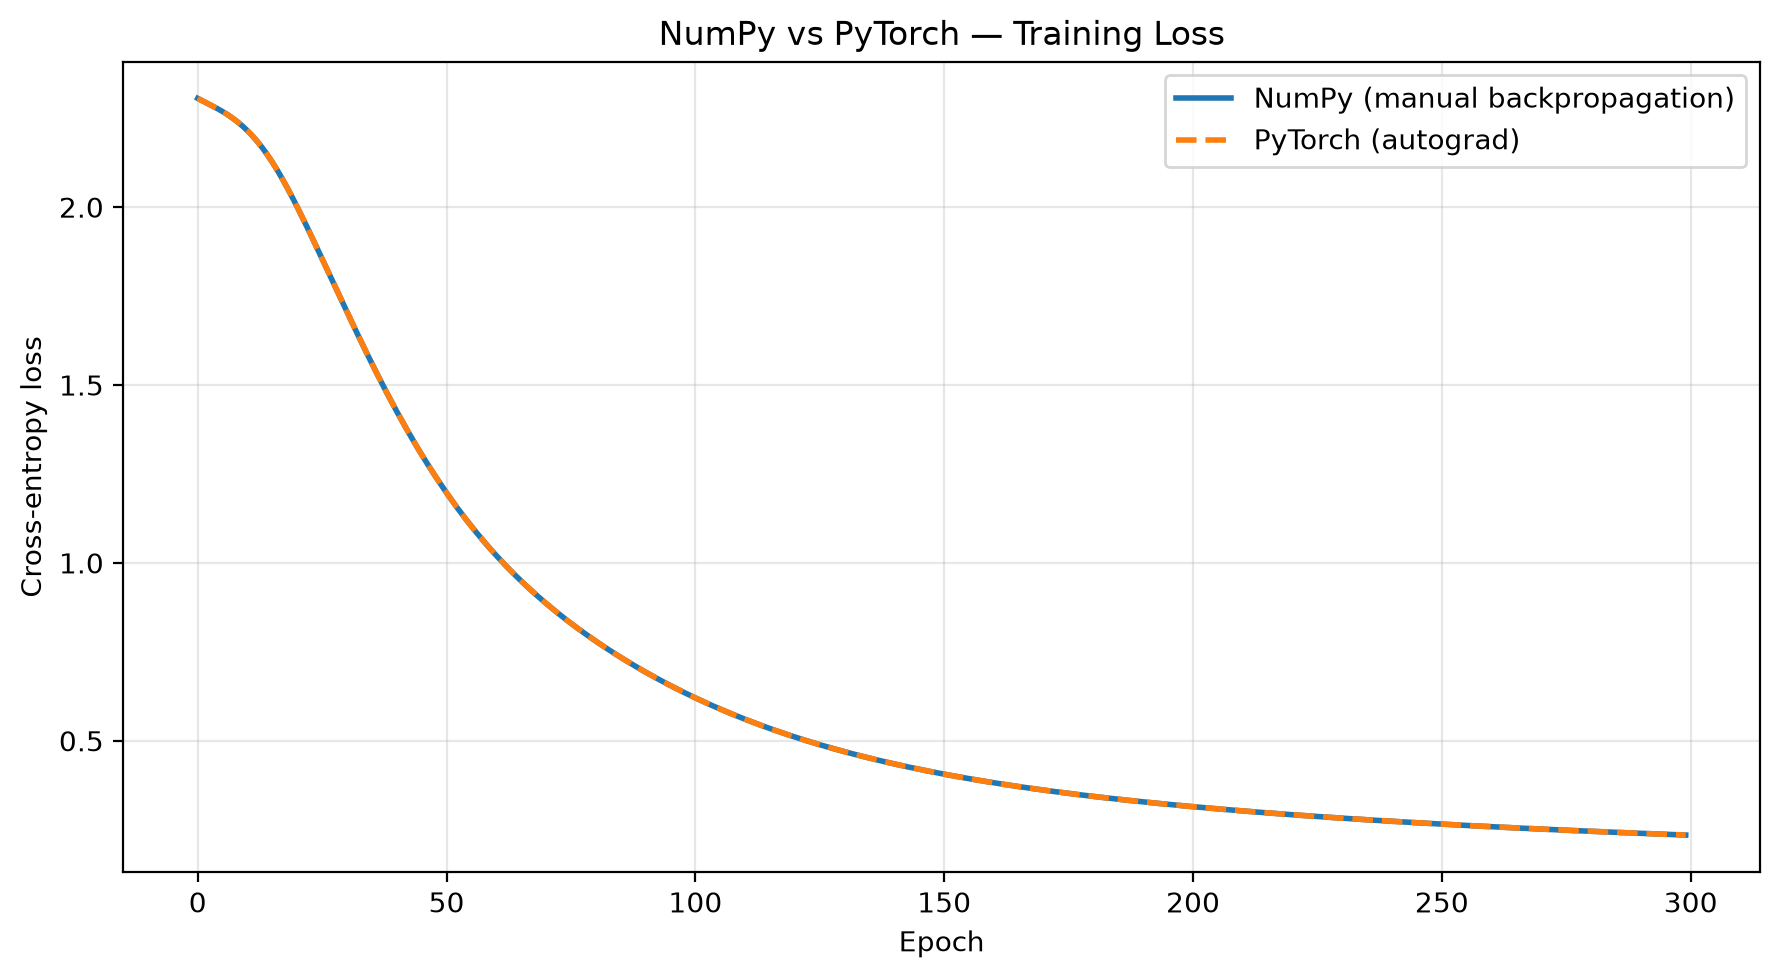


Implementation comparison:
Maximum absolute loss difference: 8.88e-16
Mean absolute loss difference:    7.54e-17
NumPy and PyTorch implementations agree.


In [8]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits


# 1. Load and prepare the Problem Set 1 dataset
digits = load_digits()

X = digits.data.astype(np.float64) / 16.0
y = digits.target

n_samples, input_dim = X.shape
hidden_dim = 5
output_dim = len(np.unique(y))

y_onehot = np.eye(output_dim)[y]

X_torch = torch.tensor(X, dtype=torch.float64)
y_torch = torch.tensor(y, dtype=torch.long)

print(f"Dataset shape: {X.shape}")
print(f"Number of classes: {output_dim}")



# 2. NumPy implementation
class NumpyMLP:
    def __init__(self, input_dim, hidden_dim, output_dim, seed=42):
        rng = np.random.default_rng(seed)

        self.W1 = rng.normal(0, 0.1, (hidden_dim, input_dim))
        self.b1 = np.zeros(hidden_dim)
        self.W2 = rng.normal(0, 0.1, (output_dim, hidden_dim))
        self.b2 = np.zeros(output_dim)

    def forward(self, X):
        self.X = X

        self.a1 = X @ self.W1.T + self.b1
        self.h = np.tanh(self.a1)

        self.a2 = self.h @ self.W2.T + self.b2

        # Stable softmax
        z = self.a2 - np.max(self.a2, axis=1, keepdims=True)
        exp_z = np.exp(z)
        self.y_hat = exp_z / np.sum(exp_z, axis=1, keepdims=True)

        return self.y_hat

    def loss(self, X, y_onehot):
        self.forward(X)

        # Stable cross-entropy
        z = self.a2
        z_max = np.max(z, axis=1, keepdims=True)

        log_sum_exp = (
            z_max
            + np.log(np.sum(np.exp(z - z_max), axis=1, keepdims=True))
        )

        return np.mean(
            log_sum_exp.ravel() - np.sum(y_onehot * z, axis=1)
        )

    def backward(self, y_onehot):
        n = self.X.shape[0]

        # Output layer
        delta2 = (self.y_hat - y_onehot) / n

        dW2 = delta2.T @ self.h
        db2 = np.sum(delta2, axis=0)

        # Hidden layer
        delta1 = (delta2 @ self.W2) * (1 - self.h**2)

        dW1 = delta1.T @ self.X
        db1 = np.sum(delta1, axis=0)

        return dW1, db1, dW2, db2

    def update(self, gradients, lr):
        dW1, db1, dW2, db2 = gradients

        self.W1 -= lr * dW1
        self.b1 -= lr * db1
        self.W2 -= lr * dW2
        self.b2 -= lr * db2



# 3. PyTorch implementation with autograd

class TorchMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, X):
        h = torch.tanh(self.fc1(X))
        logits = self.fc2(h)
        return logits



# 4. Initialize both models identically

numpy_model = NumpyMLP(
    input_dim, hidden_dim, output_dim, seed=42
)

torch_model = TorchMLP(
    input_dim, hidden_dim, output_dim
).double()

with torch.no_grad():
    torch_model.fc1.weight.copy_(torch.from_numpy(numpy_model.W1))
    torch_model.fc1.bias.copy_(torch.from_numpy(numpy_model.b1))
    torch_model.fc2.weight.copy_(torch.from_numpy(numpy_model.W2))
    torch_model.fc2.bias.copy_(torch.from_numpy(numpy_model.b2))


# 5. Train both models using full-batch SGD
epochs = 300
learning_rate = 0.5

numpy_losses = []
torch_losses = []

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(torch_model.parameters(), lr=learning_rate)

for epoch in range(epochs):

    # NumPy training
    numpy_loss = numpy_model.loss(X, y_onehot)
    numpy_losses.append(numpy_loss)

    gradients = numpy_model.backward(y_onehot)
    numpy_model.update(gradients, learning_rate)

    # PyTorch training
    optimizer.zero_grad()

    logits = torch_model(X_torch)
    torch_loss = criterion(logits, y_torch)

    torch_losses.append(torch_loss.item())

    torch_loss.backward()
    optimizer.step()

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"NumPy loss: {numpy_loss:.6f} | "
            f"PyTorch loss: {torch_loss.item():.6f}"
        )



# 6. Compare training loss curves
plt.figure(figsize=(9, 5))

plt.plot(
    numpy_losses,
    label="NumPy (manual backpropagation)",
    linewidth=2
)

plt.plot(
    torch_losses,
    "--",
    label="PyTorch (autograd)",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("NumPy vs PyTorch — Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



# 7. Verify agreement between implementations

numpy_losses = np.array(numpy_losses)
torch_losses = np.array(torch_losses)

max_abs_diff = np.max(np.abs(numpy_losses - torch_losses))
mean_abs_diff = np.mean(np.abs(numpy_losses - torch_losses))

print("\nImplementation comparison:")
print(f"Maximum absolute loss difference: {max_abs_diff:.2e}")
print(f"Mean absolute loss difference:    {mean_abs_diff:.2e}")

np.testing.assert_allclose(
    numpy_losses,
    torch_losses,
    rtol=1e-6,
    atol=1e-8
)

print("NumPy and PyTorch implementations agree.")

### Results

The NumPy and PyTorch training loss curves overlap throughout all 300 epochs. The cross-entropy loss decreases steadily, reaching approximately 0.235 at the final epoch in both implementations.

The maximum absolute difference between the loss values is $8.88 \times 10^{-16}$, while the mean difference is $7.54 \times 10^{-17}$. These differences are negligible, confirming that the manual NumPy backpropagation and PyTorch autograd produce numerically consistent results.


### Problem 6 [Python]

**Task:**
Study regularisation: train with/without L2, dropout and early stopping; produce train/validation learning curves for each and a small table of final accuracies.


Baseline: training completed (300 epochs)
L2: training completed (300 epochs)
Dropout: training completed (300 epochs)
Early stopping: training completed (300 epochs)


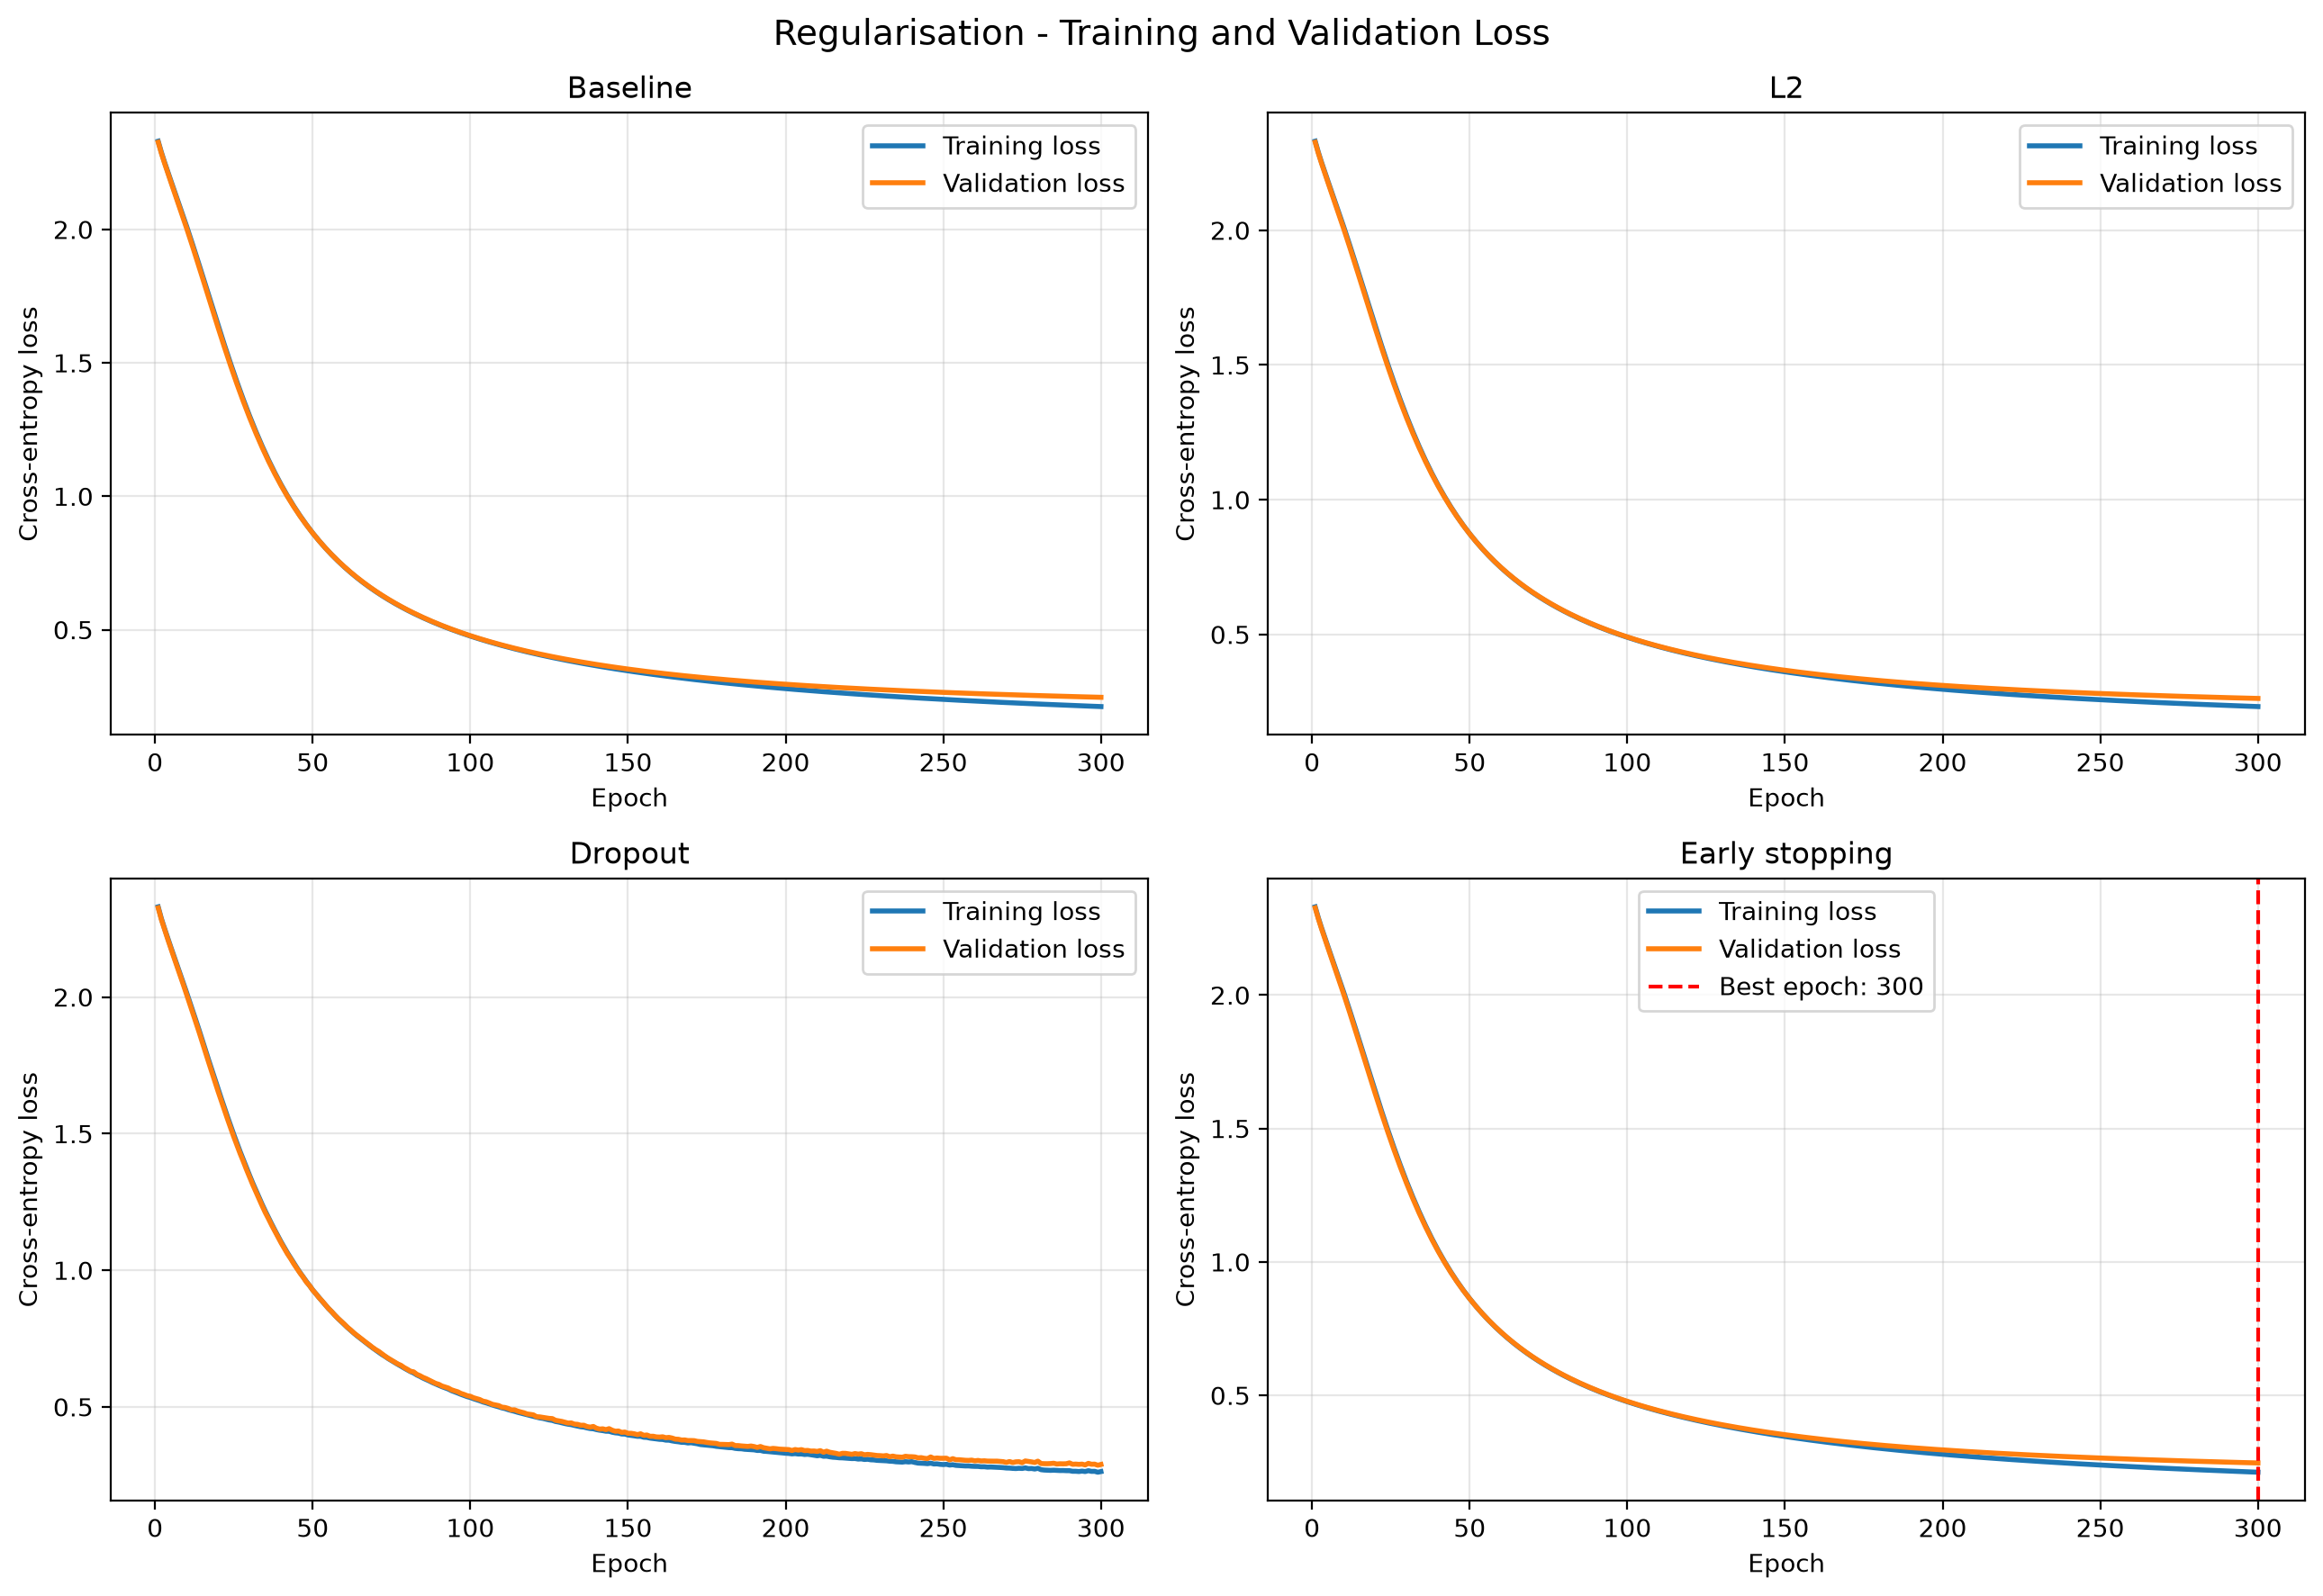


Final accuracy comparison:
Regularisation Train accuracy Validation accuracy  Epochs
      Baseline         0.9429              0.9306     300
            L2         0.9443              0.9306     300
       Dropout         0.9318              0.9139     300
Early stopping         0.9429              0.9306     300


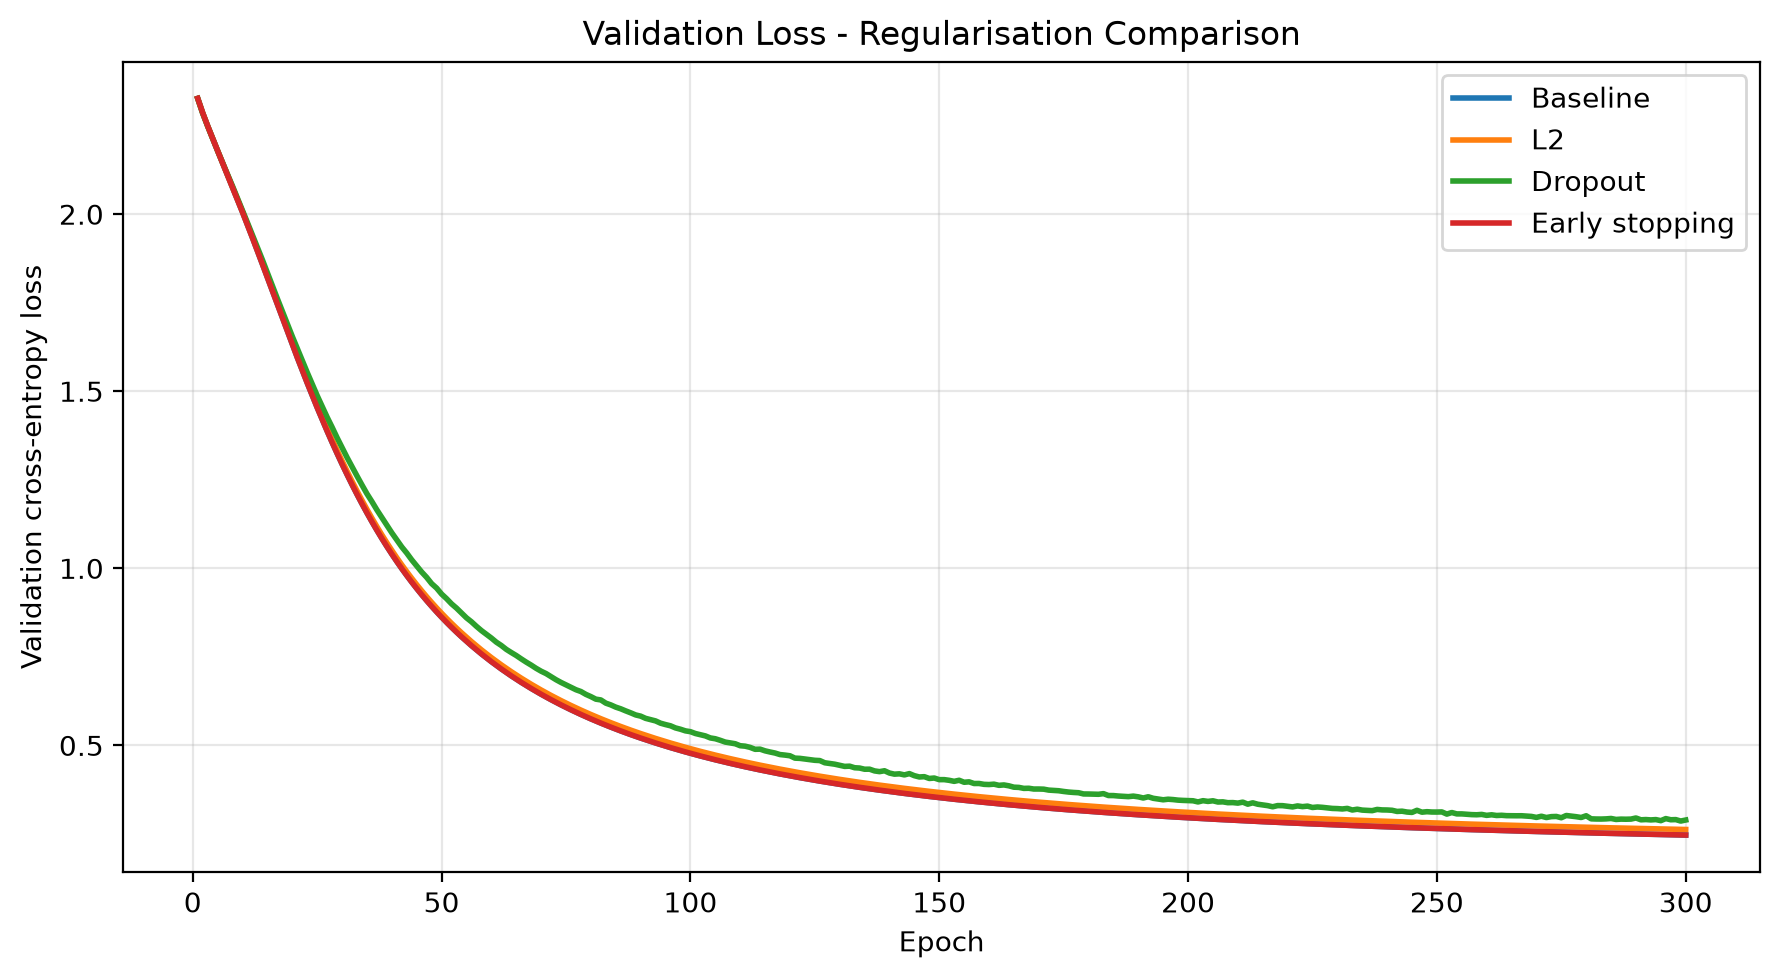

In [10]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


# 1. Load and prepare the dataset

digits = load_digits()

X = digits.data.astype(np.float64) / 16.0
y = digits.target

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = torch.tensor(X_train, dtype=torch.float64)
X_val = torch.tensor(X_val, dtype=torch.float64)

y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)

input_dim = X.shape[1]
hidden_dim = 5
output_dim = len(np.unique(y))


# 2. Two-layer MLP
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.0):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.dropout = nn.Dropout(p=dropout)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = torch.tanh(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)


# 3. Training function

def train_model(
    dropout=0.0,
    weight_decay=0.0,
    early_stopping=False,
    epochs=300,
    lr=0.5,
    patience=20
):
    torch.manual_seed(42)

    model = MLP(
        input_dim,
        hidden_dim,
        output_dim,
        dropout=dropout
    ).double()

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):

        # Training
        model.train()
        optimizer.zero_grad()

        logits = model(X_train)
        loss = criterion(logits, y_train)

        loss.backward()
        optimizer.step()

        # Evaluation
        model.eval()

        with torch.no_grad():
            train_loss = criterion(model(X_train), y_train).item()
            val_loss = criterion(model(X_val), y_val).item()

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # Save the best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }

            patience_counter = 0
        else:
            patience_counter += 1

        # Early stopping
        if early_stopping and patience_counter >= patience:
            break

    if early_stopping:
        model.load_state_dict(best_state)

    # Final accuracies
    model.eval()

    with torch.no_grad():
        train_pred = model(X_train).argmax(dim=1).numpy()
        val_pred = model(X_val).argmax(dim=1).numpy()

    train_acc = accuracy_score(y_train.numpy(), train_pred)
    val_acc = accuracy_score(y_val.numpy(), val_pred)

    return {
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "epochs": len(train_losses),
        "best_epoch": best_epoch
    }


# 4. Train regularisation variants

configurations = {
    "Baseline": {
        "dropout": 0.0,
        "weight_decay": 0.0,
        "early_stopping": False
    },
    "L2": {
        "dropout": 0.0,
        "weight_decay": 0.001,
        "early_stopping": False
    },
    "Dropout": {
        "dropout": 0.2,
        "weight_decay": 0.0,
        "early_stopping": False
    },
    "Early stopping": {
        "dropout": 0.0,
        "weight_decay": 0.0,
        "early_stopping": True
    }
}

results = {}

for name, config in configurations.items():
    results[name] = train_model(**config)
    print(f"{name}: training completed ({results[name]['epochs']} epochs)")


# 5. Training and validation learning curves
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (name, result) in zip(axes.flat, results.items()):

    epochs_range = range(1, result["epochs"] + 1)

    ax.plot(
        epochs_range,
        result["train_losses"],
        label="Training loss",
        linewidth=2
    )

    ax.plot(
        epochs_range,
        result["val_losses"],
        label="Validation loss",
        linewidth=2
    )

    if name == "Early stopping":
        ax.axvline(
            result["best_epoch"],
            color="red",
            linestyle="--",
            label=f"Best epoch: {result['best_epoch']}"
        )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Regularisation - Training and Validation Loss",
    fontsize=14
)
plt.tight_layout()
plt.show()


# 6. Final accuracy comparison
summary = pd.DataFrame([
    {
        "Regularisation": name,
        "Train accuracy": result["train_accuracy"],
        "Validation accuracy": result["val_accuracy"],
        "Epochs": result["epochs"]
    }
    for name, result in results.items()
])

print("\nFinal accuracy comparison:")
print(
    summary.to_string(
        index=False,
        formatters={
            "Train accuracy": "{:.4f}".format,
            "Validation accuracy": "{:.4f}".format
        }
    )
)


# 7. Compare validation losses
plt.figure(figsize=(9, 5))

for name, result in results.items():
    plt.plot(
        range(1, result["epochs"] + 1),
        result["val_losses"],
        label=name,
        linewidth=2
    )

plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("Validation Loss - Regularisation Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Problem 7 [Analysis]

**Task:** Using the curves from Problem 6, identify where over- and under-fitting occur and argue which regulariser helped most on this dataset and why.

---

**Overfitting and underfitting**

The training and validation loss curves decrease consistently throughout all 300 epochs, with only a small gap between them. Since the validation loss does not increase while the training loss decreases, there is no clear evidence of overfitting.

The models exhibit higher losses during the initial epochs, indicating that they have not yet learned the classification task sufficiently well. Both losses subsequently decrease, showing that the models are learning effectively. There is no strong evidence of persistent underfitting, although the small hidden layer may limit model capacity.

**Comparison of regularisation methods**

- **L2 regularisation:** Produces a slightly higher validation loss than the baseline, suggesting that weight penalisation does not improve generalisation in this experiment.
- **Dropout:** Results in the highest validation loss and slower convergence. This suggests that dropout introduces unnecessary regularisation for the relatively small network.
- **Early stopping:** Does not terminate training early, as the validation loss continues to improve until epoch 300. Consequently, its results are identical to the baseline.

**Conclusion**

The unregularised baseline achieves the lowest validation loss, with early stopping producing identical results. Neither L2 regularisation nor dropout improves generalisation.

The small difference between training and validation losses indicates that overfitting is not a significant problem for this model. Therefore, additional regularisation provides little benefit and may slightly reduce learning efficiency.
